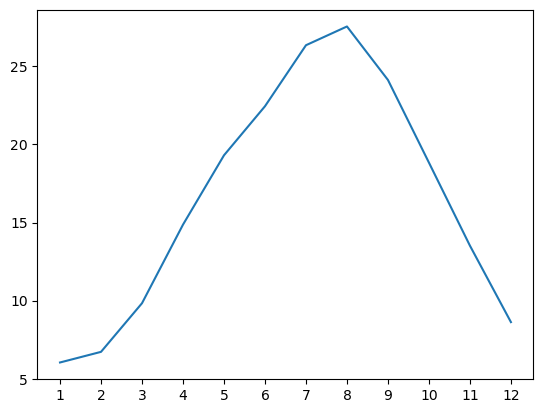

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

tokyo_temp = np.genfromtxt("Tokyo_temp.csv", 
                           delimiter=",",
                           usecols=(0, 1, 2)
                          )
y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

temp = temp[(1990 <= y)*(y <= 2019)]
m = m[(1990 <= y)*(y <= 2019)]
y = y[(1990 <= y)*(y <= 2019)]

month = np.arange(1, 13, 1)
temp_clim = np.zeros((12))
for mm in range(1, 13):
    temp_clim[mm-1] = np.nanmean(temp[m==mm], 0)
plt.plot(month, temp_clim)
plt.xticks(month)
plt.show()

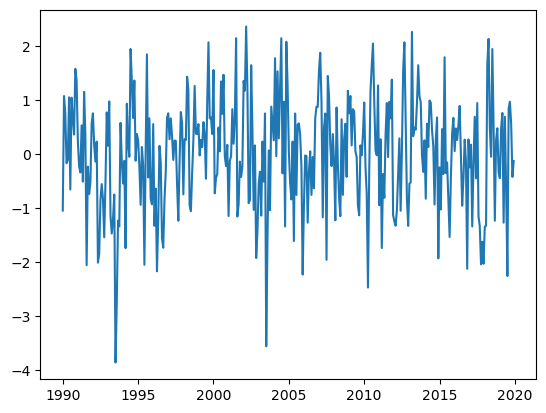

2.3931474086364484e-16


In [2]:
import numpy as np
import matplotlib.pyplot as plt

toky_temp = np.genfromtxt("Tokyo_temp.csv",
                          delimiter=",",
                          usecols=(0, 1, 2)
                         )
y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

temp = temp[(1990 <= y)*(y <= 2019)]
m = m[(1990 <= y)*(y <= 2019)]
y = y[(1990 <= y)*(y <= 2019)]

# 横坐标保存1990开始2020年结束，步长是1/12
mon = np.arange(1990, 2020, 1/12)
# tmt保存数组的大小
tmt = temp.shape
# 数组初始化为0
tempa = np.zeros((tmt))

for yy in range(1990, 2020):
    for mm in range(1, 13):
        tempa[(y==yy)*(m==mm)] = temp[(y==yy)*(m==mm)] - temp_clim[mm-1]
        
plt.plot(mon,tempa)
plt.show()
print(np.mean(tempa))

In [3]:
import numpy as np
import matplotlib.pyplot as plt

loadfile1 = 'sst_OISST.npz'
sst_dataset = np.load(loadfile1)
sst = sst_dataset['sst']
lon2 = sst_dataset['lon2']
lat2 = sst_dataset['lat2']
y = sst_dataset['y']
m = sst_dataset['m']

loadfile2 = 'sstc_OISST.npz'
sstc_dataset = np.load(loadfile2)
sst_clim = sstc_dataset['sst_clim']

# 保存sst的size
[imt, jmt, tmt] = sst.shape

ssta = np.zeros((imt, jmt, tmt))

for yy in range(1982, 2020):
    for mm in range(1, 13):
        ssta[:, :, (y==yy)*(m==mm)] = sst[:, :, (y==yy)*(m==mm)] - (sst_clim[:, :, mm-1])[:, :, np.newaxis]

savefile = 'ssta_OISST.npz'
np.savez(savefile, ssta=ssta, lon2=lon2, lat2=lat2, y=y, m=m)